# **BACKGROUND**

In the **highly competitive Food and Beverage (F&B) industry**, **data-driven** decision-making is key to maintaining **profitability and sustainable business growth**. Sedukopi, as a rapidly expanding coffee shop chain, manages a diverse menu, a network of outlets, and human resources spread across various locations.

As the number of daily transactions increases, the collected data actually holds a great deal of hidden potential. If analyzed more deeply, this sales and operational data can help Sedukopi’s management to:

1.   Identify which menu items are truly profitable for the company.
2.   Design targeted promotions based on customer habits.

# **PROBLEM IDENTIFICATION**

Currently, Sedukopi’s management is facing three real challenges in the field:

1.   The CEO suspects an imbalance in menu performance, with some menu items generating high sales volume but yielding low margins, as well as the potential existence of “hidden gems” (high-margin menu items) that are underpromoted.
2.   The marketing team plans to launch bundling packages to increase the average order value (AOV), but lacks a data foundation regarding which item combinations customers actually order together most frequently.

This portfolio project aims to answer two key questions:

1.   Which menu items are bestsellers but have low profit margins, and which “hidden gem” menu items should be promoted immediately?
2.   Which menu item pairings are the most promising for bundling?

# **DATA**
To answer the questions above, this project uses a sales dataset from Sedukopi covering the period from 2022 to 2025. This dataset includes transaction data, order details, menu items, outlets, and employees. The data will be analyzed using the Boston Matrix and Cross-Selling Analysis.

## **1.   Boston Matrix**
This model is used to classify the performance of each menu item based on two factors: popularity (sales volume) and profitability (profit margin). Menu items will be divided into 4 categories:


* **Star**: High sales and high margins. These are the best-selling, flagship menu items that are highly profitable.
* **Plowhorse**: High sales but low margins. These are menu items that customers like and order frequently, but the profit per serving is slim.
* **Puzzle**: Low sales but high margins. These are “hidden gems”—menu items with high profit potential but low purchase frequency (requiring more promotion).
* **Dog**: Low sales and low margins. These are unpopular menu items that do not generate significant profit.

## **2.   Cross-Selling Analysis**

Used to identify customer purchasing patterns in order to create bundling packages. The method involves identifying which items appear in the same shopping cart by matching order details against the order itself (self-join).


Relevant columns from the dataset used for this analysis include:
* **Order ID**: The unique ID for each shopping cart transaction
* **Quantity**: The number of products sold
* **Price**: The selling price of the product
* **Cost**: The cost of goods sold

By combining this data, we can develop more targeted business strategies, such as determining which menu items need a promotional boost and designing the most sensible bundling packages.

# **DATA UNDERSTANDING**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.stats import zscore
from collections import Counter

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/My Portofolio/F&B/Dataset.csv')
print('Jumlah baris: ', df.shape[0])
print('Jumlah kolom: ', df.shape[1])

Jumlah baris:  8123
Jumlah kolom:  10


In [ ]:
display(df.head(),df.tail())

,detail_id,order_id,item_id,name,category,quantity,subtotal,unit_price,cost_price,profit
0,DTL00001,ORD00001,ITEM012,Tubruk,Coffee,1,51000,51000,15000,36000
1,DTL00002,ORD00002,ITEM076,Cheese Cake Slice,Snack,1,28000,28000,8000,20000
2,DTL00003,ORD00003,ITEM004,Latte,Coffee,3,87000,29000,9000,20000
3,DTL00004,ORD00004,ITEM016,Iced Americano,Coffee,1,40000,40000,12000,28000
4,DTL00005,ORD00004,ITEM068,Quiche Lorraine,Makanan,1,39000,39000,12000,27000


,detail_id,order_id,item_id,name,category,quantity,subtotal,unit_price,cost_price,profit
8118,DTL08119,ORD04998,ITEM075,Muffin Blueberry,Snack,1,29000,29000,9000,20000
8119,DTL08120,ORD04999,ITEM046,Chamomile Tea,Non-Coffee,2,58000,29000,9000,20000
8120,DTL08121,ORD04999,ITEM037,Lychee Tea,Non-Coffee,2,54000,27000,8000,19000
8121,DTL08122,ORD04999,ITEM027,Vanilla Latte,Coffee,1,35000,35000,10000,25000
8122,DTL08123,ORD05000,ITEM044,Avocado Shake,Non-Coffee,1,39000,39000,12000,27000


In [ ]:
display(df.describe(), df[['name', 'category']].describe())

,quantity,subtotal,unit_price,cost_price,profit
count,8123.000000,8123.000000,8123.000000,8123.000000,8123.000000
mean,1.257417,48369.444786,38531.823218,11584.513111,26947.310107
std,0.545034,28485.082727,14252.682082,4355.546690,9908.653517
min,1.000000,18000.000000,18000.000000,5000.000000,13000.000000
25%,1.000000,28000.000000,27000.000000,8000.000000,19000.000000
50%,1.000000,39000.000000,36000.000000,11000.000000,25000.000000
75%,1.000000,58000.000000,49000.000000,15000.000000,34000.000000
max,3.000000,219000.000000,73000.000000,22000.000000,51000.000000


,name,category
count,8123,8123
unique,70,4
top,Matcha Espresso Fusion,Coffee
freq,144,2929


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8123 entries, 0 to 8122
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   detail_id   8123 non-null   object
 1   order_id    8123 non-null   object
 2   item_id     8123 non-null   object
 3   name        8123 non-null   object
 4   category    8123 non-null   object
 5   quantity    8123 non-null   int64 
 6   subtotal    8123 non-null   int64 
 7   unit_price  8123 non-null   int64 
 8   cost_price  8123 non-null   int64 
 9   profit      8123 non-null   int64 
dtypes: int64(5), object(5)
memory usage: 634.7+ KB


In [ ]:
list = ['name','category']
for i in list:
  print(df[i].unique())
  print("")

['Tubruk' 'Cheese Cake Slice' 'Latte' 'Iced Americano' 'Quiche Lorraine'
 'Iced Latte' 'Affogato' 'Donut Glazed' 'Soda Gembira' 'Roti Bakar Coklat'
 'Aeropress' 'Taro Latte' 'Nasi Goreng Kampung' 'Mango Smoothie'
 'Flat White' 'Sandwich Beef' 'Klepon' 'Caramel Macchiato' 'Cortado'
 'Avocado Shake' 'Long Black' 'Kopi Tubruk Special' 'Iced Cappuccino'
 'Salad Caesar' 'Es Jeruk' 'Vanilla Milkshake' 'Brownies Fudge'
 'Strawberry Smoothie' 'Cappuccino' 'Matcha Latte Iced' 'Piccolo'
 'Teh Tarik' 'Coklat Es' 'Matcha Espresso Fusion' 'Beef Rice Bowl'
 'Spaghetti Aglio Olio' 'Tiramisu Slice' 'Spaghetti Carbonara' 'V60'
 'Macchiato' 'Chamomile Tea' 'Red Velvet Latte' 'Mocha' 'Coklat Panas'
 'Sandwich Tuna' 'Earl Grey' 'Club Sandwich' 'Lemon Tea' 'Mie Goreng Jawa'
 'Iced Mocha' 'Es Kopi Kelapa' 'Croissant Almond' 'Sandwich Ayam'
 'Nasi Goreng Spesial' 'Pancake Maple' 'Lychee Tea' 'Croissant Butter'
 'Matcha Latte' 'Muffin Blueberry' 'Es Teh Manis' 'French Toast'
 'Cinnamon Roll' 'Kue Sus Vanilla'

# **DATA CLEANING**

**DATA DUPLICATE**

In [ ]:
df_clean = df.copy()
duplicates_count = df_clean.duplicated().sum()
persentage_duplicates = (duplicates_count / df.shape[0]) * 100

print(f'Dataset memiliki {duplicates_count} duplicates ({persentage_duplicates:.2f}% dari data).')

Dataset memiliki 0 duplicates (0.00% dari data).


Insight:

Dataset terkonfirmasi bebas dari duplikasi data.

**MISSING VALUE**

In [ ]:
df_clean.isna().sum()

,0
detail_id,0
order_id,0
item_id,0
name,0
category,0
quantity,0
subtotal,0
unit_price,0
cost_price,0
profit,0


Insight:

Dataset terkonfirmasi bebas dari nilai NULL.

**OUTLIER**

In [ ]:
numerik = df_clean.select_dtypes(include=np.number)
print(numerik.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8123 entries, 0 to 8122
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   quantity    8123 non-null   int64
 1   subtotal    8123 non-null   int64
 2   unit_price  8123 non-null   int64
 3   cost_price  8123 non-null   int64
 4   profit      8123 non-null   int64
dtypes: int64(5)
memory usage: 317.4 KB
None


**Cek Outliers dengan IQR**

In [ ]:
outliers = {}

for i in numerik.columns:
  Q1 = df_clean[i].quantile(0.25)
  Q3 = df_clean[i].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - (1.5 * IQR)
  upper_bound = Q3 + (1.5 * IQR)

  #Filter data yang diluar bound
  nilai_outlier = df_clean[(df_clean[i] < lower_bound) | (df_clean[i] > upper_bound)]
  outliers[i] = nilai_outlier[i].tolist()

# Menampilkan jumlah dan persentase outlier per kolom
for col, outlier_list in outliers.items():
    total_data = len(numerik[col])
    num_outliers = len(outlier_list)
    percentage = (num_outliers / total_data) * 100
    print(f"{col}: {num_outliers} outliers ({percentage:.2f}%)")

quantity: 1661 outliers (20.45%)
subtotal: 438 outliers (5.39%)
unit_price: 0 outliers (0.00%)
cost_price: 0 outliers (0.00%)
profit: 0 outliers (0.00%)


**Check Outliers Using Z-score**

In [ ]:
# Hitung Z-Score untuk setiap kolom numerik
z_scores = numerik.apply(zscore)

# Deteksi outlier (nilai absolut Z-Score > 3)
outliers = (z_scores.abs() > 3)

# Menampilkan jumlah outlier per kolom
outlier_counts = outliers.sum()
print(outlier_counts)

quantity      430
subtotal      214
unit_price      0
cost_price      0
profit          0
dtype: int64


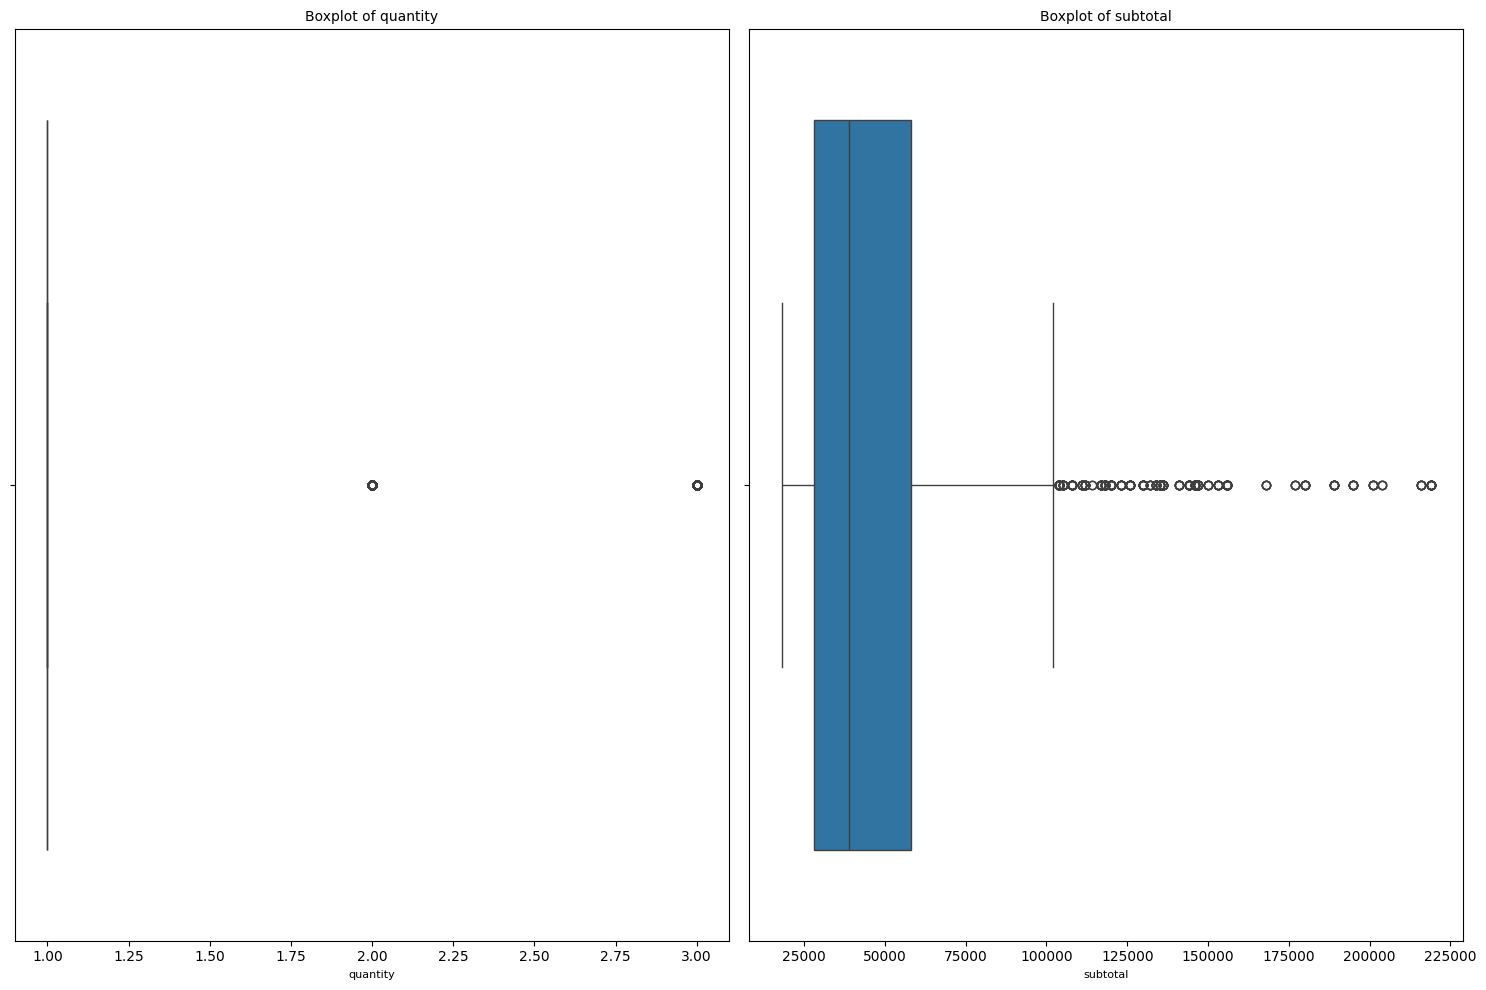

In [ ]:
df_num = df[['quantity', 'subtotal']]

# Menentukan ukuran subplot
num_cols = 2
num_rows = (len(df_num.columns) + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 10))

axes = axes.flatten()

# Membuat boxplot untuk setiap kolom numerik
for i, col in enumerate(df_num.columns):
    sns.boxplot(data=df_num[col], ax=axes[i], orient='h')
    axes[i].set_title(f'Boxplot of {col}', fontsize=10)
    axes[i].set_xlabel(col, fontsize=8)

# Hapus frame subplot sisa yang kosong
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

Insight:

No outliers were removed because, based on knowledge of the relevant field, all extreme values are still considered reasonable and relevant in the context of this analysis.

# **EDA**

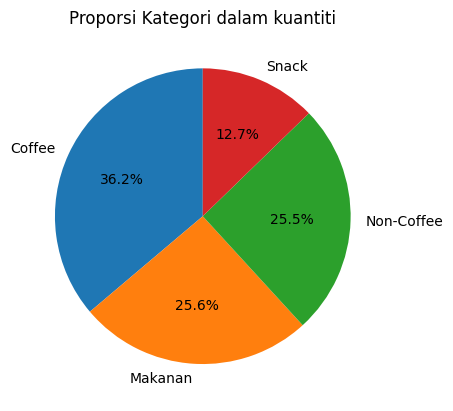

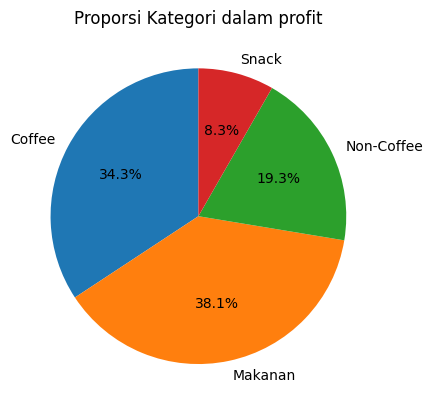

In [ ]:
# Melihat proporsi setiap kategori dalam quantity dan profit
category_quantity = df_clean.groupby('category')['quantity'].sum()
category_profit = df_clean.groupby('category')['profit'].sum()

plt.pie(category_quantity, labels=category_quantity.index, autopct='%1.1f%%', startangle=90)
plt.title('Proporsi Kategori dalam kuantiti')
plt.show()

plt.pie(category_profit, labels=category_profit.index, autopct='%1.1f%%', startangle=90)
plt.title('Proporsi Kategori dalam profit')
plt.show()

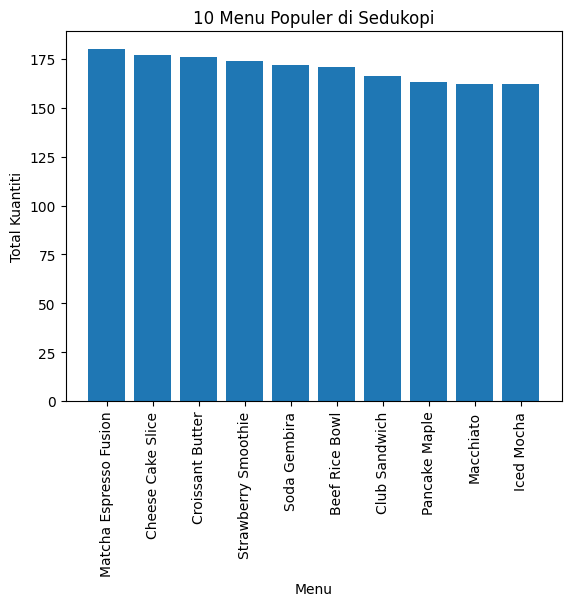

In [ ]:
#Menu populer
populer = df_clean.groupby('name')[['quantity']].sum().reset_index()
populer = populer.sort_values(by='quantity', ascending=False)
populer = populer.head(10)
plt.bar(populer['name'], populer['quantity'])
plt.xlabel('Menu')
plt.ylabel('Total Kuantiti')
plt.title('10 Menu Populer di Sedukopi')
plt.xticks(rotation=90)
plt.show()

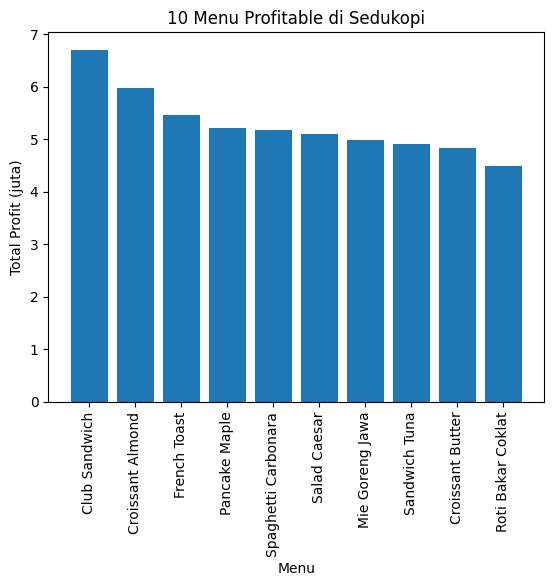

In [ ]:
#Menu paling menguntungkan
profit = df_clean.groupby('name')[['profit']].sum().reset_index()
profit = profit.sort_values(by='profit', ascending=False)
profit['profit'] = profit['profit']/1000000
profit = profit.head(10)
plt.bar(profit['name'], profit['profit'])
plt.xlabel('Menu')
plt.ylabel('Total Profit (juta)')
plt.title('10 Menu Profitable di Sedukopi')
plt.xticks(rotation=90)
plt.show()

Insight:
- The Coffee category drives sales volume, while the Food category is the largest contributor to profit. This indicates that coffee products have lower profit margins than food items.

- There is a significant difference between a product’s popularity and its contribution to profit:
  - Top 3 Best-Sellers: Matcha Espresso Fusion, Cheesecake Slice, and Butter Croissant.
  - Top 3 Most Profitable: Club Sandwich, Almond Croissant, and French Toast.

# **IN DEPTH ANALYSIS**

**Boston Matrix**

This model is used to classify the performance of each menu item based on two factors: popularity (sales volume) and profitability (profit margin). Menu items are divided into four categories: Star, Plowhorse, Puzzle, and Dog.

In [ ]:
# Merangkum total volume terjual dan total profit untuk setiap menu
menu_perf = df_clean.groupby(['item_id', 'name', 'category']).agg(
    total_volume=('quantity', 'sum'),
    total_profit=('profit', 'sum')).reset_index()

In [ ]:
# Mencari nilai tengah untuk membelah kuadran
median_volume = menu_perf['total_volume'].median()
median_profit = menu_perf['total_profit'].median()

print(f"Median Volume : {median_volume} porsi")
print(f"Median Profit : Rp {median_profit:,.0f}")

Median Volume : 144.5 porsi
Median Profit : Rp 2,873,000


In [ ]:
#Klasifikasi Matrix Boston
def classify_boston(row):
    if row['total_volume'] >= median_volume and row['total_profit'] >= median_profit:
        return 'Star'
    elif row['total_volume'] >= median_volume and row['total_profit'] < median_profit:
        return 'Plowhorse'
    elif row['total_volume'] < median_volume and row['total_profit'] >= median_profit:
        return 'Puzzle'
    else:
        return 'Dog'

In [ ]:
menu_perf = menu_perf.sort_values(by='total_profit', ascending=False).reset_index(drop=True)
menu_perf['boston_matrix'] = menu_perf.apply(classify_boston, axis=1)

In [ ]:
# Hitung total seluruh profit
grand_total_profit = menu_perf['total_profit'].sum()

# Hitung persentase kontribusi per menu dan angka kumulatifnya
menu_perf['profit_contribution_%'] = (menu_perf['total_profit'] / grand_total_profit) * 100
menu_perf['cumulative_profit_%'] = menu_perf['profit_contribution_%'].cumsum()

# Melihat 10 Menu Teratas dan kontribusinya
print("\n--- Top 10 Menu Berdasarkan Profit ---")
print(menu_perf[['name', 'boston_matrix', 'total_volume', 'total_profit', 'cumulative_profit_%']].head(10))


--- Top 10 Menu Berdasarkan Profit ---
                  name boston_matrix  total_volume  total_profit  \
0        Club Sandwich          Star           166       6700000   
1     Croissant Almond          Star           145       5967000   
2         French Toast        Puzzle           141       5457000   
3        Pancake Maple          Star           163       5207000   
4  Spaghetti Carbonara        Puzzle           134       5170000   
5         Salad Caesar        Puzzle           144       5104000   
6      Mie Goreng Jawa        Puzzle           126       4992000   
7        Sandwich Tuna        Puzzle           139       4905000   
8     Croissant Butter          Star           176       4824000   
9    Roti Bakar Coklat        Puzzle           129       4494000   

   cumulative_profit_%  
0             3.060856  
1             5.786846  
2             8.279844  
3            10.658632  
4            13.020517  
5            15.352250  
6            17.632816  
7          

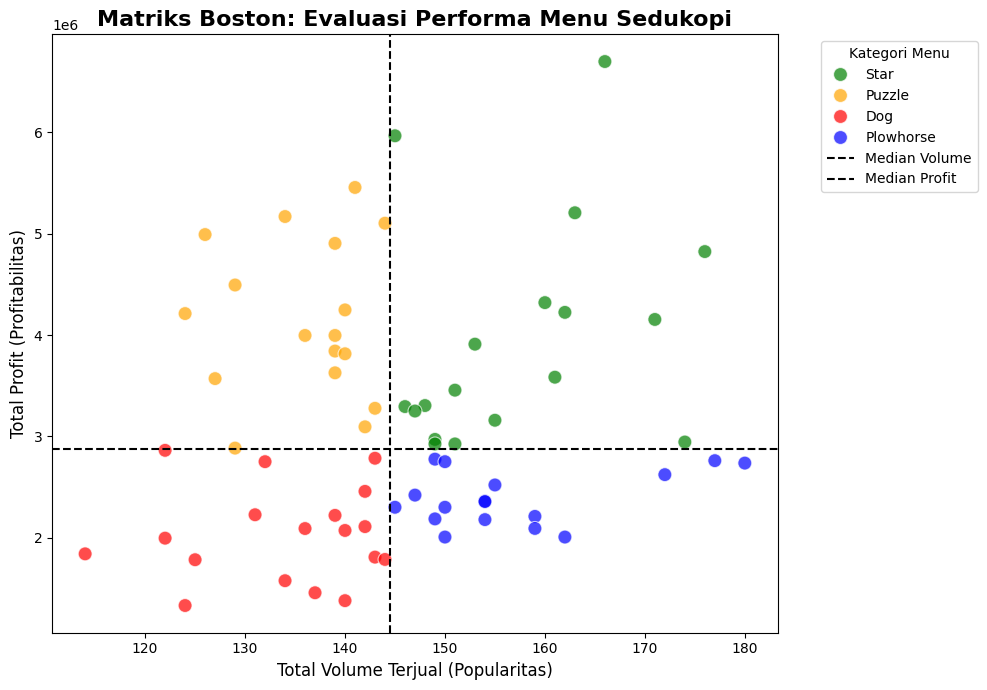

In [ ]:
plt.figure(figsize=(10, 7))

# Membuat titik sebaran (Scatter)
sns.scatterplot(
    data=menu_perf,
    x='total_volume',
    y='total_profit',
    hue='boston_matrix',
    palette={'Star': 'green', 'Plowhorse': 'blue', 'Puzzle': 'orange', 'Dog': 'red'},
    s=100, alpha=0.7
)

# Menggambar garis batas Median (Threshold)
plt.axvline(median_volume, color='black', linestyle='--', linewidth=1.5, label='Median Volume')
plt.axhline(median_profit, color='black', linestyle='--', linewidth=1.5, label='Median Profit')

# Mempercantik tampilan
plt.title('Matriks Boston: Evaluasi Performa Menu Sedukopi', fontsize=16, fontweight='bold')
plt.xlabel('Total Volume Terjual (Popularitas)', fontsize=12)
plt.ylabel('Total Profit (Profitabilitas)', fontsize=12)
plt.legend(title='Kategori Menu', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Menampilkan grafik
plt.show()

In [ ]:
# 1. Mencari Plowhorse (Volume Tinggi, Margin Tipis)
plowhorse_menu = menu_perf[menu_perf['boston_matrix'] == 'Plowhorse']
# Urutkan berdasarkan yang paling laris
plowhorse_prioritas = plowhorse_menu.sort_values(by='total_volume', ascending=False)
print("Menu Laris Margin Tipis:")
print(plowhorse_prioritas.head())

# 2. Mencari Hidden Gem (Volume Rendah, Margin Tinggi)
puzzle_menu = menu_perf[menu_perf['boston_matrix'] == 'Puzzle']
# Urutkan berdasarkan profit paling besar
puzzle_prioritas = puzzle_menu.sort_values(by='total_profit', ascending=False)
print("\nHidden Gem (Target Promosi):")
print(puzzle_prioritas.head())

#3. Mencari dog (Volume Rendah, Profit Rendah)
dog_menu = menu_perf[menu_perf['boston_matrix']=='Dog']
# Urutkan berdasarkan profit paling kecil
dog_prioritas = dog_menu.sort_values(by='total_profit', ascending=True)
print("\nMungkin perlu dihentikan:")
print(dog_prioritas.head())

Menu Laris Margin Tipis:
    item_id                    name    category  total_volume  total_profit  \
41  ITEM028  Matcha Espresso Fusion      Coffee           180       2736000   
38  ITEM076       Cheese Cake Slice       Snack           177       2760000   
42  ITEM050            Soda Gembira  Non-Coffee           172       2622000   
60  ITEM007               Macchiato      Coffee           162       2006000   
52  ITEM040              Taro Latte  Non-Coffee           159       2210000   

   boston_matrix  profit_contribution_%  cumulative_profit_%  
41     Plowhorse               1.249926            73.651053  
38     Plowhorse               1.260890            69.888484  
42     Plowhorse               1.197846            74.848899  
60     Plowhorse               0.916429            93.170636  
52     Plowhorse               1.009626            85.524891  

Hidden Gem (Target Promosi):
   item_id                 name category  total_volume  total_profit  \
2  ITEM060         F

Insight:

1. Here are menu items with high sales volume but low profit margins:
  - Matcha Espresso Fusion
  - Cheese Cake Slice
  - Soda Gembira
  - Macchiato
  - Taro Latte

Although the profit margins are low, these menu items are the foundation that drives customer traffic. Maintain their quality, and use these popular menu items as “lures” in bundled packages to promote other menu items.

2. Here are some “hidden gems” that need promotion:
  - French Toast
  - Spaghetti Carbonara
  - Caesar Salad
  - Javanese Fried Noodles
  - Tuna Sandwich
  -
These menu items are key to doubling the company’s profits. Aggressive promotion is needed, or instruct baristas/cashiers to actively recommend these items to customers.

3. Here are the items you might consider discontinuing for now, as they have low volume and profit margins:
  - Earl Grey
  - Chocolate Chip Cookies
  - Cinnamon Roll
  - Matcha Latte
  - Vanilla Cream Puffs

**Cross-Selling**

Used to analyze customer purchasing patterns in order to create bundled packages.

In [ ]:
# Membuat list menu apa saja yang dibeli di setiap order_id
transactions = df_clean.groupby('order_id')['name'].apply(lambda x: x.tolist())
pair_counts = Counter()

# Looping ke setiap keranjang belanja (struk)
for items in transactions:
    unique_items = sorted(set(items))

    # Membuat kombinasi berpasangan (2 item)
    for pair in combinations(unique_items, 2):
        pair_counts[pair] += 1

# Ubah hasil perhitungan menjadi DataFrame agar rapi
pairs_df = pd.DataFrame(pair_counts.items(), columns=['Item_Pair', 'Frequency'])

# Pisahkan pasangan item (tuple) menjadi 2 kolom berbeda (Item_1 dan Item_2)
pairs_df[['Item_1', 'Item_2']] = pd.DataFrame(pairs_df['Item_Pair'].tolist(), index=pairs_df.index)

# Rapikan susunan kolom dan urutkan dari yang paling sering dibeli bersamaan
pairs_df = pairs_df[['Item_1', 'Item_2', 'Frequency']]
pairs_df = pairs_df.sort_values(by='Frequency', ascending=False).reset_index(drop=True)

# Tampilkan 10 Pasangan Teratas
print("--- Top 10 Pasangan Menu untuk Strategi Bundling ---")
print(pairs_df.head(15))

--- Top 10 Pasangan Menu untuk Strategi Bundling ---
                    Item_1               Item_2  Frequency
0           Brownies Fudge           Iced Mocha          8
1            Chamomile Tea         Soda Gembira          7
2           Brownies Fudge           Long Black          7
3                 Affogato           Long Black          6
4                Aeropress        Sandwich Ayam          6
5                   Klepon           Taro Latte          6
6                    Latte         Soda Gembira          6
7        Cookies Chocochip               Klepon          6
8            Chamomile Tea           Iced Latte          6
9        Cheese Cake Slice           Lychee Tea          6
10           Pancake Maple            Teh Tarik          6
11              Iced Mocha  Strawberry Smoothie          6
12  Matcha Espresso Fusion                Mocha          6
13            French Toast  Strawberry Smoothie          6
14               Lemon Tea    Matcha Latte Iced          6


/tmp/ipykernel_4266/3923823229.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


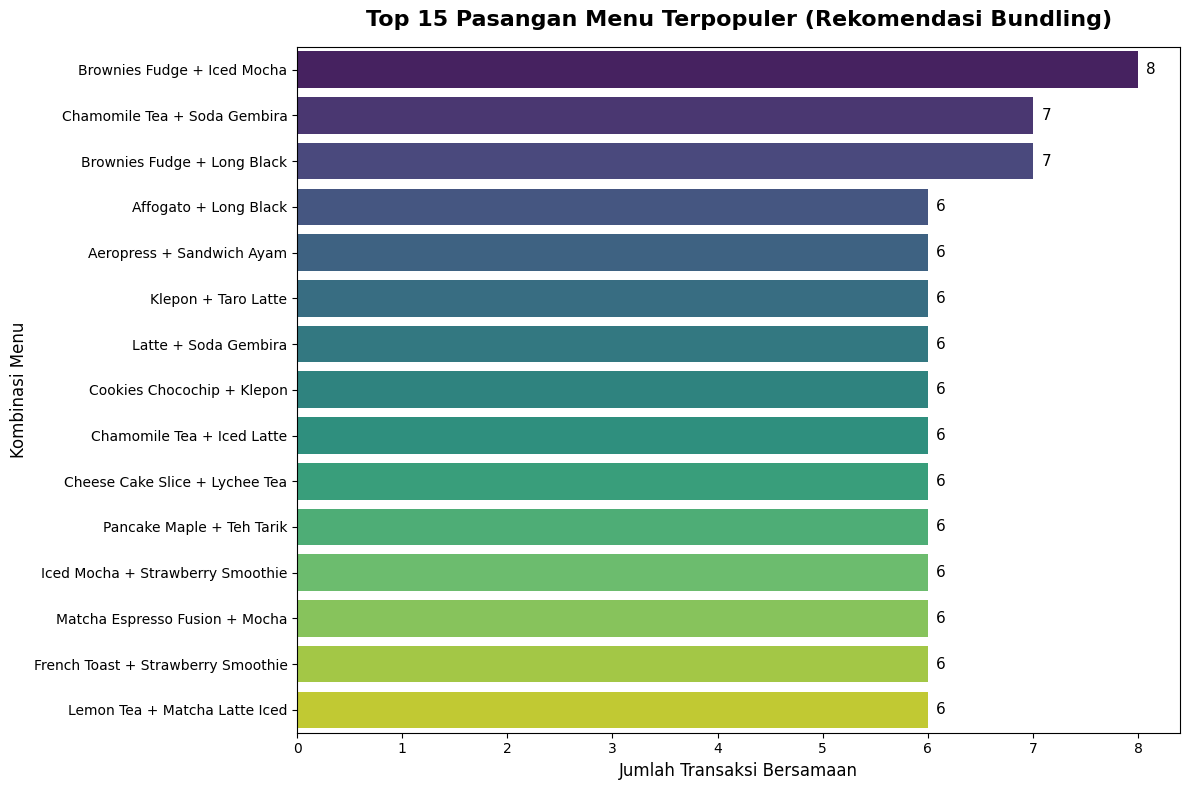

In [ ]:
# 1. Ambil 15 pasangan teratas
top_15_pairs = pairs_df.head(15).copy()

# 2. Gabungkan nama item untuk label di sumbu Y
top_15_pairs['Menu_Pair'] = top_15_pairs['Item_1'] + " + " + top_15_pairs['Item_2']

# 3. Setup ukuran canvas grafik
plt.figure(figsize=(12, 8))

# 4. Buat Bar Chart Horizontal
ax = sns.barplot(
    data=top_15_pairs,
    x='Frequency',
    y='Menu_Pair',
    palette='viridis' # Anda bisa ganti dengan 'magma', 'Blues_d', dsb.
)

# 5. Tambahkan judul dan label sumbu
plt.title('Top 15 Pasangan Menu Terpopuler (Rekomendasi Bundling)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Jumlah Transaksi Bersamaan', fontsize=12)
plt.ylabel('Kombinasi Menu', fontsize=12)

# 6. Tampilkan angka frekuensi persis di sebelah kanan setiap bar
for p in ax.patches:
    width = p.get_width()
    plt.text(
        width + (max(top_15_pairs['Frequency']) * 0.01), # Jarak teks dari ujung bar
        p.get_y() + p.get_height() / 2,
        f'{int(width)}',
        ha='left',
        va='center',
        fontsize=11
    )

# 7. Render grafik
plt.tight_layout()
plt.show()

In [ ]:
hidden_gems = ['French Toast', 'Spaghetti Carbonara', 'Salad Caesar', 'Mie Goreng Jawa', 'Sandwich Tuna']
print("--- Rekomendasi Bundling Khusus Menu Hidden Gem ---\n")

for menu in hidden_gems:
    print(f"🎯 Target Bundling: {menu}")

    pasangan = pairs_df[(pairs_df['Item_1'] == menu) | (pairs_df['Item_2'] == menu)]

    top_3_pasangan = pasangan.head(3)

    for index, row in top_3_pasangan.iterrows():
        item_pasangan = row['Item_2'] if row['Item_1'] == menu else row['Item_1']
        print(f"   + {item_pasangan} (Terjadi {row['Frequency']} kali transaksi)")
    print("-" * 40)

--- Rekomendasi Bundling Khusus Menu Hidden Gem ---

🎯 Target Bundling: French Toast
   + Strawberry Smoothie (Terjadi 6 kali transaksi)
   + Salad Caesar (Terjadi 5 kali transaksi)
   + Avocado Shake (Terjadi 4 kali transaksi)
----------------------------------------
🎯 Target Bundling: Spaghetti Carbonara
   + Club Sandwich (Terjadi 5 kali transaksi)
   + Iced Latte (Terjadi 4 kali transaksi)
   + Piccolo (Terjadi 4 kali transaksi)
----------------------------------------
🎯 Target Bundling: Salad Caesar
   + French Toast (Terjadi 5 kali transaksi)
   + Sandwich Ayam (Terjadi 4 kali transaksi)
   + Mie Goreng Jawa (Terjadi 4 kali transaksi)
----------------------------------------
🎯 Target Bundling: Mie Goreng Jawa
   + Cappuccino (Terjadi 5 kali transaksi)
   + Caramel Macchiato (Terjadi 5 kali transaksi)
   + Piccolo (Terjadi 4 kali transaksi)
----------------------------------------
🎯 Target Bundling: Sandwich Tuna
   + Spaghetti Aglio Olio (Terjadi 5 kali transaksi)
   + Nasi Goren

/tmp/ipykernel_4266/2782544353.py:81: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


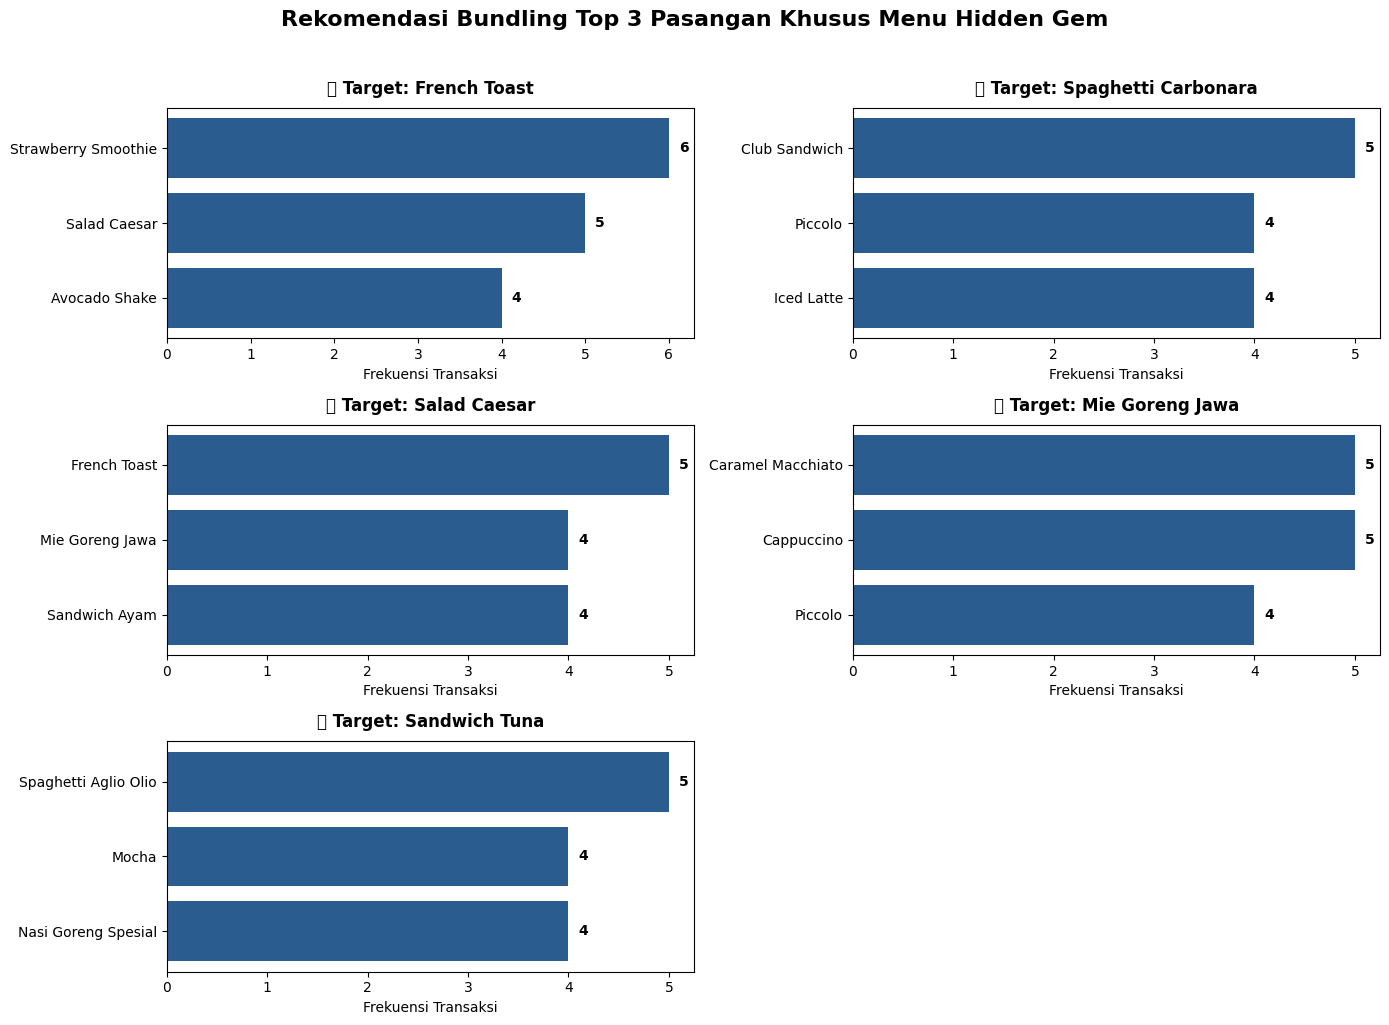

In [ ]:
#Ekstrak data top 3 pasangan untuk setiap hidden gem ke dalam DataFrame
plot_data = []
hidden_gems = [
    'French Toast',
    'Spaghetti Carbonara',
    'Salad Caesar',
    'Mie Goreng Jawa',
    'Sandwich Tuna',
]

for menu in hidden_gems:
  pasangan = pairs_df[
      (pairs_df['Item_1'] == menu) | (pairs_df['Item_2'] == menu)
  ]
  top_3_pasangan = pasangan.head(3)

  for index, row in top_3_pasangan.iterrows():
    item_pasangan = (
        row['Item_2'] if row['Item_1'] == menu else row['Item_1']
    )
    plot_data.append({
        'Hidden_Gem': menu,
        'Pasangan': item_pasangan,
        'Frequency': row['Frequency'],
    })

df_gems = pd.DataFrame(plot_data)
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()  # Meratakan array 2D axes agar mudah di-looping

#visualisasi grafik untuk tiap menu hidden gem
for i, menu in enumerate(hidden_gems):
  ax = axes[i]
  sub_df = df_gems[df_gems['Hidden_Gem'] == menu].sort_values(
      by='Frequency', ascending=True
  )

  if not sub_df.empty:
    bars = ax.barh(sub_df['Pasangan'], sub_df['Frequency'], color='#2b5c8f')
    ax.set_title(
        f'🎯 Target: {menu}', fontsize=12, fontweight='bold', pad=10
    )
    ax.set_xlabel('Frekuensi Transaksi', fontsize=10)

    max_val = sub_df['Frequency'].max()
    for bar in bars:
      width = bar.get_width()
      ax.text(
          width + (max_val * 0.02),
          bar.get_y() + bar.get_height() / 2,
          f'{int(width)}',
          va='center',
          ha='left',
          fontsize=10,
          fontweight='bold',
      )
  else:
    ax.text(
        0.5,
        0.5,
        'Belum ada data transaksi',
        ha='center',
        va='center',
        fontsize=10,
    )
    ax.set_title(f'🎯 Target: {menu}', fontsize=12, fontweight='bold')

axes[5].axis('off')

plt.suptitle(
    'Rekomendasi Bundling Top 3 Pasangan Khusus Menu Hidden Gem',
    fontsize=16,
    fontweight='bold',
    y=1.02,
)
plt.tight_layout()
plt.show()

Insight:

“Hidden gem” restaurants can use this bundled offer as a promotional strategy to boost their sales.

# **CONCLUSION**

The Coffee category serves as the primary driver of sales volume, while the Food category is the largest contributor to profit. This indicates that coffee products have lower profit margins than food products.

There is a significant difference between a product’s popularity and its contribution to profit:

- Top 3 Best-Selling Items: Matcha Espresso Fusion, Cheesecake Slice, and Butter Croissant.
- Top 3 Most Profitable Items: Club Sandwich, Almond Croissant, and French Toast.


# **INSIGHT**

Based on these findings, menu performance can be classified into three main segments:
- High Volume & Low Margin: Matcha Espresso Fusion, Cheese Cake Slice, Soda Gembira, Macchiato, and Taro Latte.
- Hidden Gems (High Margin & Low Volume): French Toast, Spaghetti Carbonara, Caesar Salad, Javanese Fried Noodles, and Tuna Sandwich.
- Low Volume & Low Profit: Earl Grey, Chocolate Chip Cookies, Cinnamon Roll, Matcha Latte, and Vanilla Cream Puffs.

# **RECOMMENDATIONS**
- Use the “Lure Menu” Strategy: Maintain the quality of high-volume menu items, as they serve as customer traffic drivers. Use these popular items as “lures” in promotional packages to promote other menu items.
- Aggressive Promotion & Cross-Selling for “Hidden Gems”: These menu items are key to multiplying the company’s profits. Instruct cashiers to actively offer these menu items and implement the following transaction-data-driven bundling strategies:
    * Pair French Toast with a Strawberry Smoothie / Caesar Salad / Avocado Shake.
    * Pair Spaghetti Carbonara with a Club Sandwich / Iced Latte / Piccolo.
    * Pair Caesar Salad with French Toast / Chicken Sandwich / Javanese Fried Noodles.
    * Javanese Fried Noodles paired with Cappuccino / Caramel Macchiato / Piccolo.
    * Tuna Sandwich paired with Spaghetti Aglio Olio / Special Fried Rice / Mocha.
- Evaluate Low-Performing Menu Items: Temporarily suspend menu items with low volume and profit to optimize raw material costs and minimize potential losses.